#### Facility Problem using NSGA

The objective function
- Minimize $f_1(x_1, x_2) =\sqrt{(x_1 -3)^2 + (x_2 -1)^2}$, distance between company facilities.  
- Maximize $f_2(x_1, x_2) = -\sqrt{(x_1 -2)^2 + (x_2 -4)^2}$, distance between a new facility and a competitor's facility.

s.t.

- $g_1(x_1, x_2) = x_1 + 2*x_2 -6 <=0$, zoning regulations

- $g_2(x_1, x_2) = 2*x_1 -x_2 -2 <=0$, environmental constraints or property boundaries

- $0 \le x_1, x_2 \le 5$, boundary constrains

In [ ]:
!pip install pymoo > /dev/null

In [ ]:
import numpy as np
from pymoo.core.problem import ElementwiseProblem

from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PolynomialMutation
from pymoo.operators.repair.rounding import RoundingRepair
from pymoo.operators.sampling.rnd import FloatRandomSampling

from pymoo.termination import get_termination
from pymoo.optimize import minimize
from pymoo.visualization.scatter import Scatter
from pymoo.decomposition.asf import ASF

import math
import matplotlib.pyplot as plt

In [ ]:
class Facility(ElementwiseProblem):
    def __init__(self):
        super().__init__(n_var=2, n_obj=2, n_ieq_constr=2,
                         xl=np.array([0,0]), xu=np.array([5,5]))

    def _evaluate(self, x, out, *args, **kwargs):
        f1 = math.sqrt((x[0] - 3)**2 + (x[1] - 1)**2)
        f2 = -math.sqrt((x[0] - 2)**2 + (x[1] - 4)**2)
        g1 = x[0] + 2*x[1] - 6
        g2 = 2*x[0] - x[1] - 2
        out["F"] = [f1, f2]
        out["G"] = [g1, g2]

problem = Facility()

algorithm = NSGA2(
    pop_size=50,
    #n_offsprings=10,
    sampling=FloatRandomSampling(),
    #crossover=SBX(prob=0.8, eta=15),
    crossover=SBX(prob=0.8),
    mutation=PolynomialMutation(prob=0.6, repair=RoundingRepair()),
    eliminate_duplicates=True
)
termination = get_termination("n_gen", 50)

res = minimize(
            problem,
            algorithm,
            termination,
            seed=1,
            save_history=True,
            verbose=True)
X = res.X
F = res.F

n_gen  |  n_eval  | n_nds  |     cv_min    |     cv_avg    |      eps      |   indicator  
     1 |       50 |      3 |  0.000000E+00 |  4.0133037898 |             - |             -
     2 |       83 |      5 |  0.000000E+00 |  1.9383798402 |  0.2958735650 |         ideal
     3 |       91 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f
     4 |       99 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f
     5 |      107 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f
     6 |      114 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f
     7 |      123 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f
     8 |      131 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f
     9 |      138 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f
    10 |      145 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f

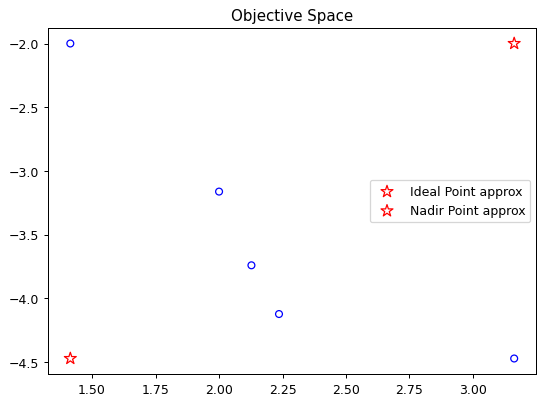

In [ ]:
approx_ideal = F.min(axis=0)
approx_nadir = F.max(axis=0)

plt.figure(figsize=(7, 5), dpi=90)
plt.scatter(F[:, 0], F[:, 1], s=30, facecolors='none', edgecolors='b')
plt.scatter(approx_ideal[0], approx_ideal[1], facecolors='none', edgecolors='r', marker='*', s=100, label='Ideal Point approx')
plt.scatter(approx_nadir[0], approx_nadir[1], facecolors='none', edgecolors='r', marker='*', s=100, label='Nadir Point approx')
plt.title("Objective Space")
plt.legend()
plt.show()

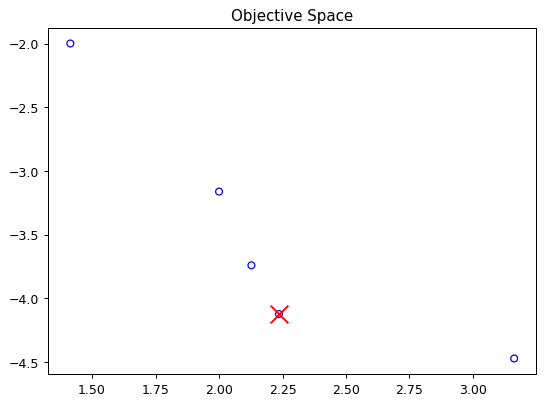

In [ ]:
decomp = ASF()
weights = np.array([0.2, 0.8])

nF = (F -approx_ideal) / (approx_nadir - approx_ideal)
i = decomp.do(nF, 1/weights).argmin()

plt.figure(figsize=(7, 5), dpi=90)
plt.scatter(F[:, 0], F[:, 1], s=30, facecolors='none', edgecolors='b')
plt.scatter(F[i, 0], F[i, 1], color='r', s=200, marker='x')
plt.title("Objective Space")
plt.show()

In [ ]:
soln = np.asarray(X[i], dtype='int')
print('Best solution found')
print('Optimal facility location', soln)
print('Optimal distance between facilities', round(F[i, 0], 2))
print('Optimal distance between new facility and competitors', round(-F[i, 1], 2))

Best solution found
Optimal facility location [1 0]
Optimal distance between facilities 2.24
Optimal distance between new facility and competitors 4.12
